# PCA and Clustering — Iris Dataset

This notebook applies **Principal Component Analysis (PCA)** and clustering to the Iris dataset.

The analysis follows the practical task by exploring the original features, examining their correlations, standardising the data, reducing it to three principal components, and then applying hierarchical and K-Means clustering.


## 1. Import the required libraries


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score


## 2. Load and inspect the Iris dataset

Load the supplied Iris dataset and inspect the first observations, dimensions, column names and data types.


In [2]:
iris_df = pd.read_csv("Iris.csv")

display(iris_df.head())

print("Dataset shape:", iris_df.shape)
print("\nColumns:", iris_df.columns.tolist())
print("\nData types:")
print(iris_df.dtypes)


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


Dataset shape: (150, 6)

Columns: ['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']

Data types:
Id                 int64
SepalLengthCm    float64
SepalWidthCm     float64
PetalLengthCm    float64
PetalWidthCm     float64
Species           object
dtype: object


## 3. Explore the features and statistical properties

`Id` is only an observation identifier, while `Species` is the known class label. Neither is included as an input feature for PCA.

The four measurements used in the analysis are:

- Sepal length
- Sepal width
- Petal length
- Petal width


In [3]:
features = [
    "SepalLengthCm",
    "SepalWidthCm",
    "PetalLengthCm",
    "PetalWidthCm"
]

X = iris_df[features].copy()

pd.set_option("display.float_format", lambda x: f"{x:.2f}")

stats = X.describe().loc[["mean", "std", "min", "max"]].T
display(stats)

print("\nMissing values:")
print(X.isnull().sum())


,mean,std,min,max
SepalLengthCm,5.84,0.83,4.30,7.90
SepalWidthCm,3.05,0.43,2.00,4.40
PetalLengthCm,3.76,1.76,1.00,6.90
PetalWidthCm,1.20,0.76,0.10,2.50



Missing values:
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
dtype: int64


## 4. Examine correlations between the original features

A correlation matrix shows the direction and strength of the linear relationships between all four Iris measurements.

Positive values indicate that two variables tend to increase together, while negative values indicate that one tends to decrease as the other increases.


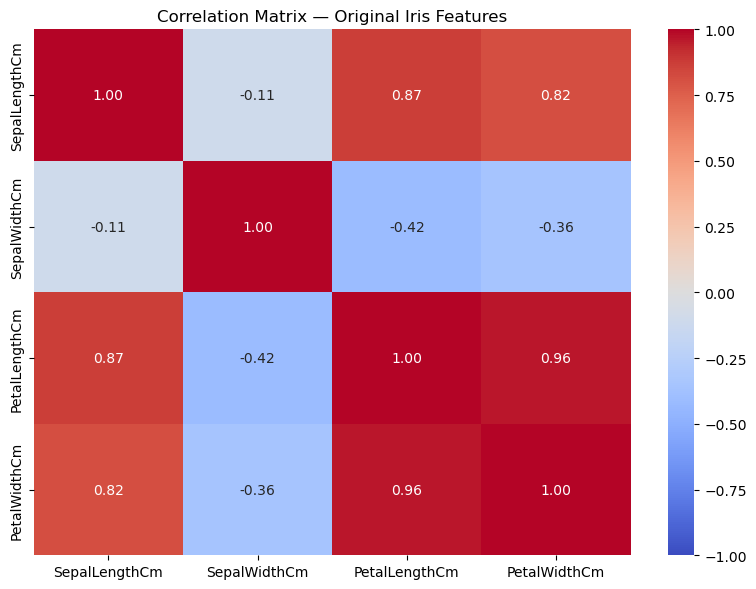

In [4]:
original_corr = X.corr()

plt.figure(figsize = (8, 6))

sns.heatmap(
    original_corr,
    annot = True,
    cmap = "coolwarm",
    center = 0,
    vmin = -1,
    vmax = 1,
    fmt = ".2f"
)

plt.title("Correlation Matrix — Original Iris Features")
plt.tight_layout()
plt.show()


### Correlation observations

petal length and petal width are strongly positively related, and sepal length also has a positive relationship with the petal measurements.

This correlation is one reason PCA can be useful: PCA constructs new components that summarise shared variation while being mutually uncorrelated.


## 5. Standardise the data

PCA is affected by the scale of the variables. Standardisation gives each feature a mean of approximately 0 and a standard deviation of approximately 1, preventing variables with larger scales from dominating the PCA solution.


In [5]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(
    X_scaled,
    columns = features
)

display(X_scaled_df.head())


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,-0.90,1.03,-1.34,-1.31
1,-1.14,-0.12,-1.34,-1.31
2,-1.39,0.34,-1.40,-1.31
3,-1.51,0.11,-1.28,-1.31
4,-1.02,1.26,-1.34,-1.31


## 6. Apply PCA with three components

The task specifies `n_components = 3`.

PCA transforms the four correlated original measurements into three new principal components. Each component captures a portion of the total variation in the data.


In [6]:
pca = PCA(n_components = 3)

X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    X_pca,
    columns = ["PC1", "PC2", "PC3"]
)

display(pca_df.head())


,PC1,PC2,PC3
0,-2.26,0.51,0.12
1,-2.09,-0.66,0.23
2,-2.37,-0.32,-0.05
3,-2.30,-0.58,-0.10
4,-2.39,0.67,-0.02


### Explained variance


In [7]:
explained_variance = pd.DataFrame({
    "Principal Component": ["PC1", "PC2", "PC3"],
    "Explained Variance Ratio": pca.explained_variance_ratio_,
    "Cumulative Explained Variance": np.cumsum(pca.explained_variance_ratio_)
})

display(explained_variance)

print(
    f"Total variance explained by the first three components: "
    f"{pca.explained_variance_ratio_.sum():.4f}"
)


,Principal Component,Explained Variance Ratio,Cumulative Explained Variance
0,PC1,0.73,0.73
1,PC2,0.23,0.96
2,PC3,0.04,0.99


Total variance explained by the first three components: 0.9948


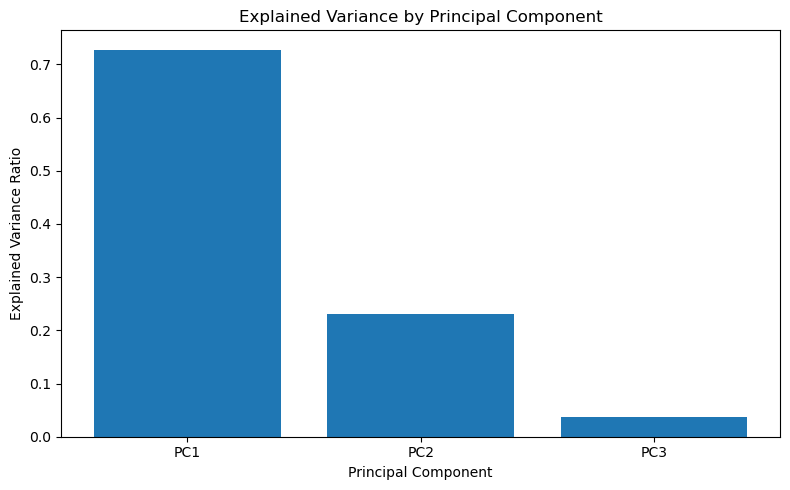

In [8]:
plt.figure(figsize = (8, 5))

plt.bar(
    ["PC1", "PC2", "PC3"],
    pca.explained_variance_ratio_
)

plt.ylabel("Explained Variance Ratio")
plt.xlabel("Principal Component")
plt.title("Explained Variance by Principal Component")
plt.tight_layout()
plt.show()


## 7. Create a PCA biplot

A biplot combines:

- the observations projected onto the first two principal components; and
- arrows representing the contribution (loadings) of the original variables.

The species labels are used **only for visual interpretation** here; they were not used to calculate the PCA components.


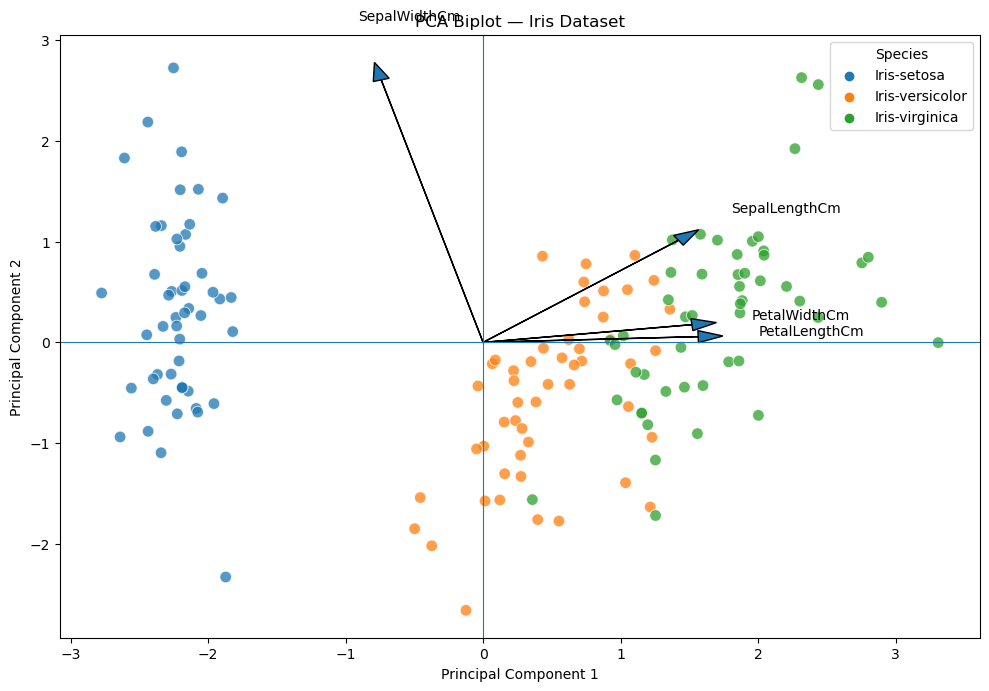

In [9]:
# Add species only for colouring the visualisation.
plot_df = pca_df.copy()
plot_df["Species"] = iris_df["Species"].values

plt.figure(figsize = (10, 7))

sns.scatterplot(
    data = plot_df,
    x = "PC1",
    y = "PC2",
    hue = "Species",
    s = 70,
    alpha = 0.75
)

# PCA loadings for PC1 and PC2.
loadings = pca.components_.T[:, :2]

# Scale arrows so that they are visible on the score plot.
arrow_scale = 3

for i, feature in enumerate(features):
    plt.arrow(
        0,
        0,
        loadings[i, 0] * arrow_scale,
        loadings[i, 1] * arrow_scale,
        head_width = 0.12,
        length_includes_head = True
    )

    plt.text(
        loadings[i, 0] * arrow_scale * 1.15,
        loadings[i, 1] * arrow_scale * 1.15,
        feature,
        fontsize = 10
    )

plt.axhline(0, linewidth = 0.8)
plt.axvline(0, linewidth = 0.8)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Biplot — Iris Dataset")
plt.legend(title = "Species")
plt.tight_layout()
plt.show()


## 8. K-Means clustering on the PCA-transformed data

The Iris dataset contains three known species, so we ask K-Means to find **three clusters**. Importantly, `Species` is not supplied to the clustering algorithm.

The cluster labels are discovered solely from the three PCA components.


In [10]:
kmeans = KMeans(
    n_clusters = 3,
    random_state = 42,
    n_init = 10
)

kmeans_clusters = kmeans.fit_predict(pca_df)

pca_df["KMeans Cluster"] = kmeans_clusters

kmeans_silhouette = silhouette_score(
    pca_df[["PC1", "PC2", "PC3"]],
    kmeans_clusters
)

print(f"K-Means silhouette score: {kmeans_silhouette:.4f}")


C:\Users\3829151\AppData\Local\anaconda3\Anaconda\Lib\site-packages\joblib\externals\loky\backend\context.py:110: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\3829151\AppData\Local\anaconda3\Anaconda\Lib\site-packages\joblib\externals\loky\backend\context.py", line 199, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\3829151\AppData\Local\anaconda3\Anaconda\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\3829151\AppData\Local\anaconda3\Anaconda\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\38291

K-Means silhouette score: 0.4651


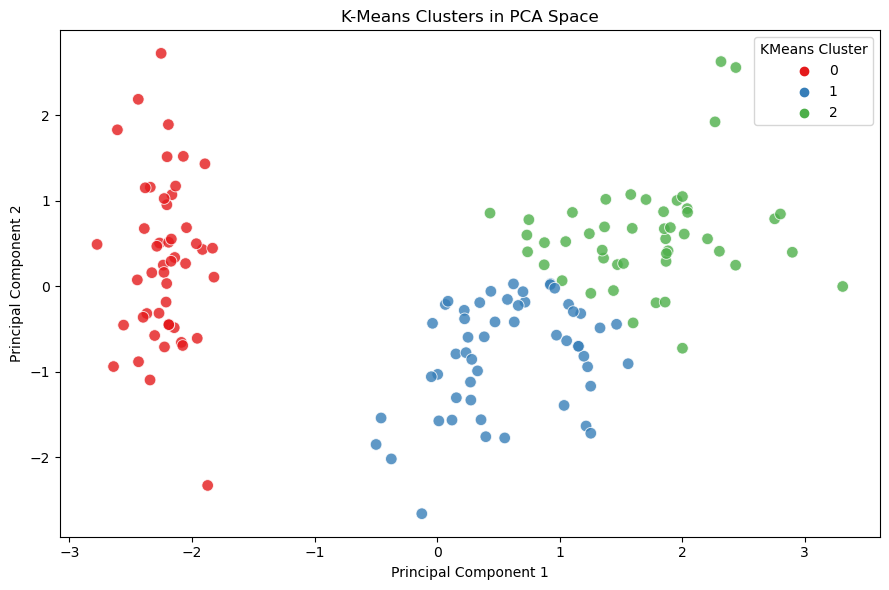

In [11]:
plt.figure(figsize = (9, 6))

sns.scatterplot(
    data = pca_df,
    x = "PC1",
    y = "PC2",
    hue = "KMeans Cluster",
    palette = "Set1",
    s = 70,
    alpha = 0.8
)

plt.title("K-Means Clusters in PCA Space")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.tight_layout()
plt.show()


## 9. Hierarchical clustering on the PCA-transformed data

Agglomerative hierarchical clustering is also fitted with three clusters. Ward linkage is used because it forms clusters by minimising increases in within-cluster variance using Euclidean geometry.


In [12]:
hierarchical = AgglomerativeClustering(
    n_clusters = 3,
    linkage = "ward"
)

hierarchical_clusters = hierarchical.fit_predict(
    pca_df[["PC1", "PC2", "PC3"]]
)

pca_df["Hierarchical Cluster"] = hierarchical_clusters

hierarchical_silhouette = silhouette_score(
    pca_df[["PC1", "PC2", "PC3"]],
    hierarchical_clusters
)

print(
    f"Hierarchical clustering silhouette score: "
    f"{hierarchical_silhouette:.4f}"
)


Hierarchical clustering silhouette score: 0.4632


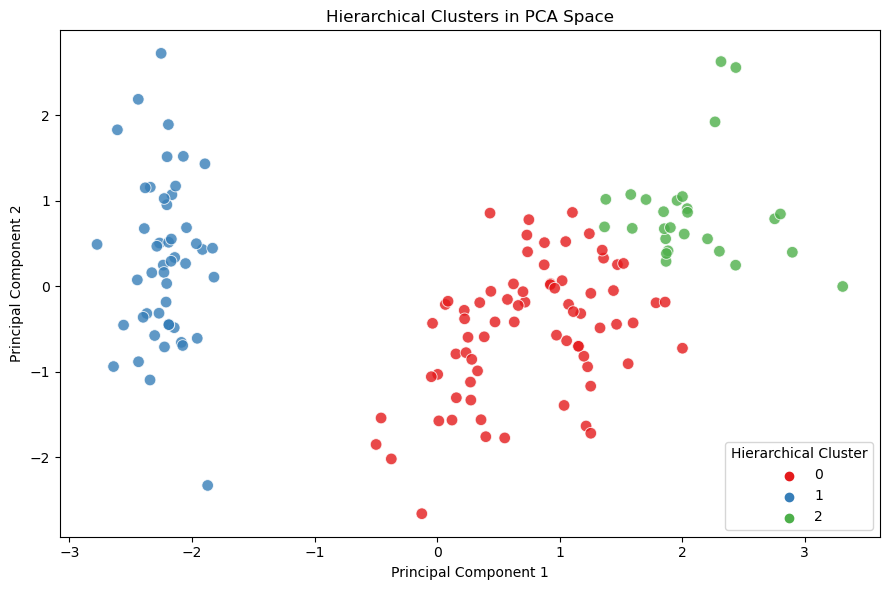

In [13]:
plt.figure(figsize = (9, 6))

sns.scatterplot(
    data = pca_df,
    x = "PC1",
    y = "PC2",
    hue = "Hierarchical Cluster",
    palette = "Set1",
    s = 70,
    alpha = 0.8
)

plt.title("Hierarchical Clusters in PCA Space")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.tight_layout()
plt.show()


## 10. Did the clustering techniques identify the three species?

A cross-tabulation shows how the unsupervised cluster assignments correspond to the known species. The **Adjusted Rand Index (ARI)** is also reported as an additional measure of agreement. An ARI closer to 1 indicates stronger agreement between the discovered clusters and the known classes.


In [14]:
comparison_df = pd.DataFrame({
    "Species": iris_df["Species"],
    "KMeans Cluster": kmeans_clusters,
    "Hierarchical Cluster": hierarchical_clusters
})

print("K-Means clusters vs species:")
display(pd.crosstab(
    comparison_df["Species"],
    comparison_df["KMeans Cluster"]
))

print("\nHierarchical clusters vs species:")
display(pd.crosstab(
    comparison_df["Species"],
    comparison_df["Hierarchical Cluster"]
))

kmeans_ari = adjusted_rand_score(
    comparison_df["Species"],
    comparison_df["KMeans Cluster"]
)

hierarchical_ari = adjusted_rand_score(
    comparison_df["Species"],
    comparison_df["Hierarchical Cluster"]
)

print(f"K-Means Adjusted Rand Index: {kmeans_ari:.4f}")
print(f"Hierarchical Adjusted Rand Index: {hierarchical_ari:.4f}")


K-Means clusters vs species:


KMeans Cluster,0,1,2
Species,,,
Iris-setosa,50,0,0
Iris-versicolor,0,39,11
Iris-virginica,0,14,36



Hierarchical clusters vs species:


Hierarchical Cluster,0,1,2
Species,,,
Iris-setosa,0,50,0
Iris-versicolor,50,0,0
Iris-virginica,23,0,27


K-Means Adjusted Rand Index: 0.6201
Hierarchical Adjusted Rand Index: 0.6537


### Interpretation of the clustering

One Iris species is typically much more clearly separated in the PCA space, while the other two show greater overlap. Therefore, the clustering techniques can identify meaningful natural groups in the measurements, but the unsupervised clusters should not automatically be treated as exact replacements for the known species labels.


## 11. Correlation matrix after PCA

PCA constructs orthogonal principal components. As a result, the transformed components should have correlations very close to zero.

We recreate the correlation plot using only `PC1`, `PC2` and `PC3`.


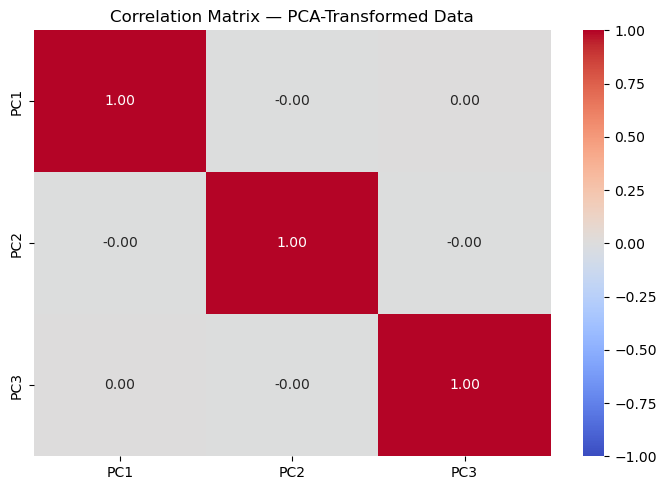

In [15]:
pca_corr = pca_df[["PC1", "PC2", "PC3"]].corr()

plt.figure(figsize=(7, 5))

sns.heatmap(
    pca_corr,
    annot = True,
    cmap = "coolwarm",
    center = 0,
    vmin = -1,
    vmax = 1,
    fmt = ".2f"
)

plt.title("Correlation Matrix — PCA-Transformed Data")
plt.tight_layout()
plt.show()


## 12. Compare the original and PCA correlation structures

The original Iris measurements contain several substantial positive and negative correlations. This means that some variables contain overlapping information.

After PCA, the off-diagonal correlations between `PC1`, `PC2` and `PC3` should be approximately zero. The transformed variables are therefore non-redundant in the linear-correlation sense.

PCA has reduced the original four measurements to three uncorrelated components while retaining most of the variation in the dataset. This demonstrates how PCA can reduce dimensionality and redundancy before subsequent analysis such as clustering.
